# Week 5 Project — Linear Model Pipeline
**CodeTrade AI/ML Internship · Phase 2 · Week 5**

**Dataset:** California Housing (`california_housing.csv`, 5,000 districts, 8 numeric features, 1 target).
Source: the CSV supplied with the task (the classic scikit-learn / 1990 US Census California housing data).

**Workflow:** explore → freeze split → dumb baseline → plain model → Ridge/Lasso → tune alpha with CV → one Pipeline → interpret → single final test evaluation.

## Setup

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline

pd.set_option('display.width', 140)
RANDOM_STATE = 42

# Part 1 — Baseline before beauty
## Task 01 — Load, explore, and define the target

In [20]:
df = pd.read_csv('california_housing.csv')
print('shape:', df.shape)
df.head()

shape: (5000, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,3.7056,22.0,4.4502,1.1416,1773.0,3.0922,40.02,-122.25,1.7255
1,4.8575,36.0,5.7551,1.0897,199.0,3.6810,37.17,-118.79,2.9542
2,3.3045,9.0,8.6213,1.1102,754.0,3.5749,33.68,-115.29,2.1390
3,2.9988,16.0,6.0610,1.1367,310.0,4.7781,36.92,-122.10,1.9076
4,5.2304,6.0,5.2884,1.1086,1322.0,2.5858,41.01,-123.05,2.9634


In [21]:
print(df.head().to_string())
print()
print(df.dtypes.to_string())
print()
print('missing values per column:')
print(df.isna().sum().to_string())
print('total missing:', df.isna().sum().sum())
print('duplicate rows:', df.duplicated().sum())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  MedHouseVal
0  3.7056      22.0    4.4502     1.1416      1773.0    3.0922     40.02    -122.25       1.7255
1  4.8575      36.0    5.7551     1.0897       199.0    3.6810     37.17    -118.79       2.9542
2  3.3045       9.0    8.6213     1.1102       754.0    3.5749     33.68    -115.29       2.1390
3  2.9988      16.0    6.0610     1.1367       310.0    4.7781     36.92    -122.10       1.9076
4  5.2304       6.0    5.2884     1.1086      1322.0    2.5858     41.01    -123.05       2.9634

MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64

missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
total missing: 0
duplicate ro

**Missing values:** none, and every column is numeric, so no imputation or encoding is needed.

**Feature meanings (needed for interpretation in Part 2):**

| Feature | Meaning |
|---|---|
| `MedInc` | Median household income in the block group (units of $10,000) |
| `HouseAge` | Median age of houses in the block group (years) |
| `AveRooms` | Average number of rooms per household |
| `AveBedrms` | Average number of bedrooms per household |
| `Population` | Block group population |
| `AveOccup` | Average number of household members (occupants per household) |
| `Latitude` / `Longitude` | Geographic location of the block group (north / east-west position) |
| **`MedHouseVal`** | **Target — median house value (units of $100,000)** |

**Target definition (one sentence):** *We predict `MedHouseVal`, the median house value of a California census block group in units of $100,000; a higher value means a more expensive neighbourhood (e.g. 2.5 = $250,000).*

In [22]:
print(df.describe().T.round(3).to_string())

              count      mean      std     min      25%       50%       75%       max
MedInc       5000.0     3.510    2.189    0.50    1.913     3.069     4.618    15.000
HouseAge     5000.0    26.226   14.639    1.00   13.000    26.000    39.000    51.000
AveRooms     5000.0     5.428    1.203    2.00    4.615     5.398     6.240     9.240
AveBedrms    5000.0     1.106    0.147    0.80    1.001     1.105     1.206     1.634
Population   5000.0  1401.835  993.938  100.00  665.000  1180.500  1891.000  6000.000
AveOccup     5000.0     2.998    0.792    1.00    2.461     2.992     3.527     6.270
Latitude     5000.0    37.301    2.768   32.51   34.900    37.350    39.730    42.000
Longitude    5000.0  -119.328    2.857 -124.30 -121.780  -119.330  -116.880  -114.300
MedHouseVal  5000.0     2.210    1.003    0.15    1.498     2.093     2.812     5.000


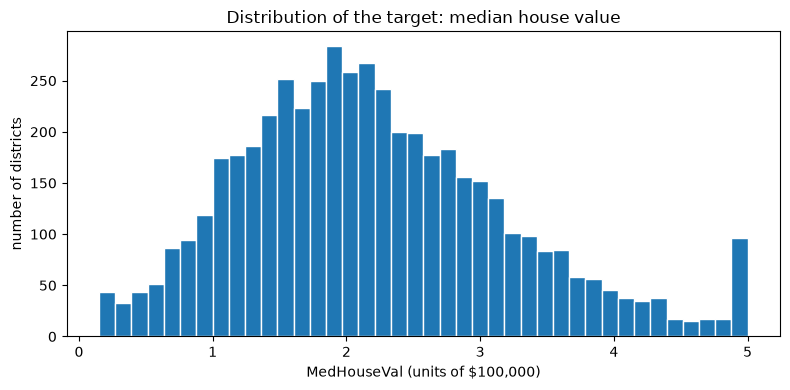

target skew: 0.568
rows capped at the max value of 5.0 : 74


In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df['MedHouseVal'], bins=40, edgecolor='white')
ax.set_title('Distribution of the target: median house value')
ax.set_xlabel('MedHouseVal (units of $100,000)')
ax.set_ylabel('number of districts')
plt.tight_layout()
plt.show()
print('target skew:', round(df['MedHouseVal'].skew(), 3))
print('rows capped at the max value of', df['MedHouseVal'].max(), ':', int((df['MedHouseVal'] == df['MedHouseVal'].max()).sum()))

**Is the target sensible?** Yes: values are positive, right-skewed (most districts are cheap-to-moderate, a tail of expensive ones) and there is a visible spike at 5.0 — the original census data is *capped* at $500,000. A linear model will under-predict those capped districts a little; we note this as a limitation. We check the target distribution *before* modelling so that we know the scale, skew and capping, and can choose a sensible metric (R²) and interpret errors correctly.

## Task 02 — Make the train/test split once, and freeze the test set

In [24]:
X = df.drop(columns='MedHouseVal')
y = df['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('y_train:', y_train.shape, '| y_test:', y_test.shape)

X_train: (4000, 8) | X_test: (1000, 8)
y_train: (4000,) | y_test: (1000,)


**What each part is for**

| Part | Purpose |
|---|---|
| **Train** (80%) | Learning: fit coefficients, scaler statistics. |
| **Validation / CV** (folds *inside* train) | Choosing: comparing models, tuning alpha. |
| **Test** (20%) | One single final check at the very end (Task 09). |

**Why split before any scaling or data-derived choice?** Anything computed from the data (means/std for scaling, chosen features, alpha) that sees the test rows lets information about the test set leak into training. That is **data leakage**: the test score becomes optimistic because the test set was no longer "unseen".

> **MISTAKE 2 — TUNING ON THE TEST SET.** From here on the test set is locked. It is touched exactly once, in Task 09.

## Task 03 — Build a dumb baseline first

In [25]:
baseline = DummyRegressor(strategy='mean')
base_scores = cross_val_score(baseline, X_train, y_train, cv=5)
print('baseline fold R2:', base_scores.round(4))
print('baseline CV R2  :', base_scores.mean().round(3))

baseline fold R2: [-0.0034 -0.     -0.     -0.0002 -0.0051]
baseline CV R2  : -0.002


**Baseline CV R² ≈ 0.00 (slightly negative).** Predicting the training mean for everybody explains none of the variance — this is our **floor**. R² *rises* as the model improves (1.0 = perfect, 0 = no better than the mean, negative = worse than the mean). Every real model must beat this, otherwise something is wrong.

`cross_val_score` splits the training data into 5 folds, trains on 4 and validates on 1, rotating 5 times. Unlike a single split it uses all training rows for validation once and gives a mean *and* a spread, so the estimate is far less dependent on one lucky/unlucky split.

> **MISTAKE 1 — SKIPPING THE BASELINE.** Done: the baseline is the measuring stick for everything that follows.

## Task 04 — One plain model, and feel the problem

In [37]:
lr = LinearRegression()
lr.fit(X_train, y_train)
plain_scores = cross_val_score(lr, X_train, y_train, cv=5)
print('plain LR CV R2:', plain_scores.mean().round(3))
print('baseline CV R2:', base_scores.mean().round(3))
print()
print('coef range:', lr.coef_.min().round(4), 'to', lr.coef_.max().round(4))
print()
print('RAW (unscaled) coefficients vs feature scale:')
raw = pd.DataFrame({'raw_coef': lr.coef_, 'feature_std': X_train.std().values}, index=X.columns)
raw['abs_coef'] = raw['raw_coef'].abs()
print(raw.round(5).to_string())

plain LR CV R2: 0.84
baseline CV R2: -0.002

coef range: -0.1419 to 0.4048

RAW (unscaled) coefficients vs feature scale:
            raw_coef  feature_std  abs_coef
MedInc       0.40478      2.17406   0.40478
HouseAge     0.01158     14.65481   0.01158
AveRooms     0.02807      1.21077   0.02807
AveBedrms    0.01282      0.14789   0.01282
Population  -0.00000    986.23674   0.00000
AveOccup    -0.14188      0.79060   0.14188
Latitude    -0.05373      2.77628   0.05373
Longitude   -0.05934      2.86530   0.05934


**What the plain model shows.** It beats the baseline by a huge margin (CV R² ≈ 0.84 vs ≈ 0.00), so there is real linear signal in this data.

**The scale problem:** the raw coefficient range here (≈ −0.14 to 0.40) is not 'absurd' — this dataset is milder than most — but the raw coefficients still cannot be compared. `Population` has a coefficient of ≈ 0 while `MedInc` is ≈ 0.40 — not because Population "doesn't matter", but because `Population` is measured in the thousands (std ≈ 1,000) while `MedInc` is measured in single digits (std ≈ 2.2). A coefficient is "effect per *one unit* of the feature", so its size depends on the feature's units. Coefficients are only comparable after **standardisation**.

Linear models are scale-sensitive because the coefficient (and, with regularisation, the *penalty on it*) depends on units; tree models only look at split thresholds/orderings, so they are scale-invariant.

> ### ✅ End of Part 1 checkpoint
> Exploration ✔ · frozen split ✔ · recorded baseline ✔ · plain model score ✔

# Part 2 — Regularised variants, tune, interpret, deliver
## Task 05 — Add Ridge and Lasso

In [27]:
scaled_plain = make_pipeline(StandardScaler(), LinearRegression())
scaled_ridge = make_pipeline(StandardScaler(), Ridge())   # default alpha = 1.0
scaled_lasso = make_pipeline(StandardScaler(), Lasso())   # default alpha = 1.0

plain_cv = cross_val_score(scaled_plain, X_train, y_train, cv=5).mean()
ridge_cv = cross_val_score(scaled_ridge, X_train, y_train, cv=5).mean()
lasso_cv_default = cross_val_score(scaled_lasso, X_train, y_train, cv=5).mean()

print('Baseline CV     :', base_scores.mean().round(3))
print('Plain (scaled)  :', plain_cv.round(3))
print('Ridge  CV       :', ridge_cv.round(3))
print('Lasso  CV       :', lasso_cv_default.round(3))

Baseline CV     : -0.002
Plain (scaled)  : 0.84
Ridge  CV       : 0.84
Lasso  CV       : -0.002


In [28]:
scaled_ridge.fit(X_train, y_train)
scaled_lasso.fit(X_train, y_train)
scaled_plain.fit(X_train, y_train)

coef_table = pd.DataFrame({
    'Plain (scaled)': scaled_plain[-1].coef_,
    'Ridge (alpha=1)': scaled_ridge[-1].coef_,
    'Lasso (alpha=1)': scaled_lasso[-1].coef_,
}, index=X.columns)
print(coef_table.round(4).to_string())
print()
print('exact zeros -> Ridge:', int((scaled_ridge[-1].coef_ == 0).sum()),
      '| Lasso:', int((scaled_lasso[-1].coef_ == 0).sum()))

            Plain (scaled)  Ridge (alpha=1)  Lasso (alpha=1)
MedInc              0.8799           0.8797              0.0
HouseAge            0.1696           0.1696              0.0
AveRooms            0.0340           0.0340              0.0
AveBedrms           0.0019           0.0019              0.0
Population         -0.0022          -0.0022              0.0
AveOccup           -0.1122          -0.1121              0.0
Latitude           -0.1491          -0.1491              0.0
Longitude          -0.1700          -0.1700              0.0

exact zeros -> Ridge: 0 | Lasso: 8


**Observations**

* **Scaled plain = unscaled plain (0.84)** — ordinary least squares has no penalty, so rescaling features only rescales the coefficients; predictions are identical. That is why scaling is *not necessarily* needed for `LinearRegression`, but **is required for Ridge/Lasso**: their penalty is applied to the coefficient size, so unscaled features would be penalised unfairly according to their units.
* **Ridge (alpha=1)** keeps all 8 coefficients non-zero and matches the plain model (0.84): with 4,000 rows and only 8 features there is little overfitting to cure.
* **Lasso (alpha=1)** is *far too strong*: it shrinks **every** coefficient to exactly zero, so it collapses into the mean-predicting baseline (CV R² ≈ 0). This is a perfect illustration of why alpha must be tuned.
* **Why zeros?** Lasso uses an L1 penalty (sum of |coef|), whose geometry has "corners" on the axes, so the optimum often lands exactly at zero. Ridge uses an L2 penalty (sum of coef²), which shrinks smoothly toward zero but never reaches it exactly.

**alpha trade-off in plain words:** alpha controls *simplicity vs. fit*. Small alpha → trust the data, large coefficients, risk of overfitting. Large alpha → force small coefficients, simpler model, risk of underfitting.

## Task 06 — Tune the best regularised variant with cross-validation

In [29]:
alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10]

lasso_cv = make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=5))
lasso_cv.fit(X_train, y_train)          # training part only

best_alpha = lasso_cv.named_steps['lassocv'].alpha_
lasso_coefs = lasso_cv.named_steps['lassocv'].coef_
print('Lasso best alpha :', best_alpha)
print('Lasso best CV R2 :', cross_val_score(lasso_cv, X_train, y_train, cv=5).mean().round(3))
print('zeroed coefficients:', int((lasso_coefs == 0).sum()), 'of', len(lasso_coefs))
print(pd.Series(lasso_coefs, index=X.columns).round(4).to_string())

Lasso best alpha : 0.001
Lasso best CV R2 : 0.84
zeroed coefficients: 0 of 8
MedInc        0.8788
HouseAge      0.1686
AveRooms      0.0330
AveBedrms     0.0009
Population   -0.0012
AveOccup     -0.1111
Latitude     -0.1481
Longitude    -0.1690


In [30]:
# Mean CV R2 for every alpha in the grid (this is what LassoCV compares)
lcv = lasso_cv.named_steps['lassocv']
cv_curve = pd.DataFrame({'alpha': lcv.alphas_, 'mean_CV_MSE': lcv.mse_path_.mean(axis=1)}).sort_values('alpha')
print(cv_curve.to_string(index=False))

  alpha  mean_CV_MSE
 0.0001     0.159672
 0.0010     0.159642
 0.0100     0.160040
 0.1000     0.211999
 1.0000     1.003493
10.0000     1.003493


In [31]:
# Same honest tuning for Ridge so the comparison is fair
ridge_alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
ridge_tuned = make_pipeline(StandardScaler(), RidgeCV(alphas=ridge_alphas, cv=5))
ridge_tuned.fit(X_train, y_train)
print('Ridge best alpha :', ridge_tuned.named_steps['ridgecv'].alpha_)
print('Ridge best CV R2 :', cross_val_score(ridge_tuned, X_train, y_train, cv=5).mean().round(3))

Ridge best alpha : 1.0
Ridge best CV R2 : 0.84


**Result.** Tuned Lasso picks **alpha = 0.001** (a small penalty) and zeroes **no** coefficient; its CV R² (≈ 0.84) equals the plain model. Tuned Ridge picks alpha = 1 and also scores ≈ 0.84. Regularisation does not *improve* accuracy here, because the model is low-dimensional and not overfitting — an honest finding. Population is the one feature shrunk to almost nothing (≈ −0.001 in standardised units).

* **Larger alpha** → coefficients shrink toward zero (Lasso: more exact zeros) → simpler, higher bias. **Smaller alpha** → coefficients approach the plain least-squares ones → lower bias, higher variance.
* **Why CV and not a single split, and never the test set?** One split can be lucky/unlucky; CV averages over 5. Choosing alpha on the test set would make the test score optimistic (Mistake 2) since the test set would have influenced the model.

## Task 07 — Wrap it in one clean sklearn Pipeline

In [32]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LassoCV(alphas=alphas, cv=5)),
])
pipeline.fit(X_train, y_train)

pipeline_cv = cross_val_score(pipeline, X_train, y_train, cv=5)
print('Pipeline CV R2   :', pipeline_cv.mean().round(3))
print('Earlier Lasso CV :', cross_val_score(lasso_cv, X_train, y_train, cv=5).mean().round(3))
print('chosen alpha     :', pipeline.named_steps['model'].alpha_)
print(pipeline)

Pipeline CV R2   : 0.84
Earlier Lasso CV : 0.84
chosen alpha     : 0.001
Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 LassoCV(alphas=[0.0001, 0.001, 0.01, 0.1, 1, 10], cv=5))])


The Pipeline's CV score matches the earlier tuned-Lasso score, as expected: it is the same model, now one object.

**Why the scaler inside a Pipeline stops leakage:** inside `cross_val_score` the scaler is re-fitted on each *training fold only* and merely applied to the validation fold; at the end `pipeline.score(X_test, ...)` applies the scaler fitted on `X_train` — the test set never influences the mean/std. **Fit vs. refit in `cross_val_score`:** `pipeline.fit(X_train, y_train)` trains once on all training rows (the model we keep); `cross_val_score` *clones* the pipeline and re-fits it 5 times on subsets purely to estimate performance, leaving our fitted pipeline untouched.

## Task 08 — Interpret the model, do not just report a number

MedInc        0.8788
Longitude    -0.1690
HouseAge      0.1686
Latitude     -0.1481
AveOccup     -0.1111
AveRooms      0.0330
Population   -0.0012
AveBedrms     0.0009


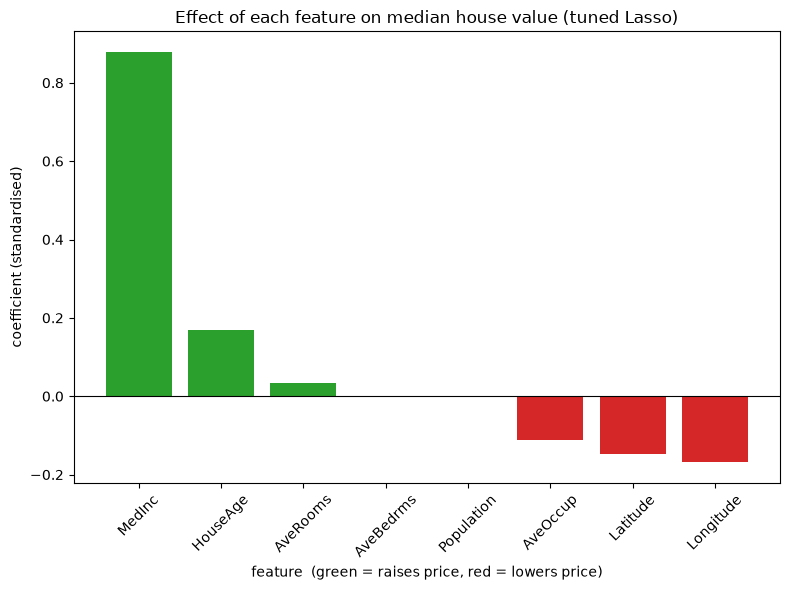

In [33]:
coefs = pipeline.named_steps['model'].coef_
coef_series = pd.Series(coefs, index=X.columns).sort_values(key=np.abs, ascending=False)
print(coef_series.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 6))
colors = ['tab:green' if c > 0 else 'tab:red' for c in coefs]
ax.bar(X.columns, coefs, color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Effect of each feature on median house value (tuned Lasso)')
ax.set_ylabel('coefficient (standardised)')
ax.set_xlabel('feature  (green = raises price, red = lowers price)')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
fig.savefig('coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation** (coefficients are per +1 standard deviation of the feature, holding the others fixed; target in $100,000):

* **`MedInc` is by far the strongest driver (≈ +0.88).** A district whose median income is one standard deviation higher is predicted to be ≈ $88,000 more expensive. Very confident: largest effect, stable across alpha.
* **`HouseAge` (≈ +0.17) pushes prices up** moderately; **`AveRooms` (≈ +0.03)** slightly up. `AveBedrms` and `Population` are close to zero, i.e. almost irrelevant once the other features are in the model (Lasso at the tuned alpha shrinks them to ≈ 0).
* **Location matters and is negative:** `Longitude` (≈ −0.17), `Latitude` (≈ −0.15) — moving north/east is associated with cheaper districts (the expensive coast is south-west) — and `AveOccup` (≈ −0.11): crowded households mean cheaper areas.
* **Confidence:** high for the sign and rough size of `MedInc`, `Latitude`, `Longitude`, `AveOccup`, `HouseAge`; lower for `AveRooms`/`AveBedrms` because they are correlated with each other (the coefficient can be split between them). Latitude/Longitude are only a *linear* proxy for geography, and these are associations, not causes.

**Why standardised coefficients:** only after standardising does "one unit" mean the same thing (one std dev) for every feature, so bar heights are fairly comparable.

**Manager's question this chart answers:** *"What drives house prices in California, and what can we ignore?"* → income first, then location and house age; household crowding pulls prices down; room counts and population add almost nothing.

## Task 09 — Final score, comparison table, deliverable

In [34]:
# The ONLY time the test set is used: one evaluation of the chosen Pipeline.
final_test_score = pipeline.score(X_test, y_test)
print('FINAL test R2:', round(final_test_score, 3))

FINAL test R2: 0.838


In [35]:
ridge_tuned_cv = cross_val_score(ridge_tuned, X_train, y_train, cv=5).mean()
lasso_tuned_cv = cross_val_score(pipeline, X_train, y_train, cv=5).mean()

comparison = pd.DataFrame({
    'Model': [
        'Baseline (DummyRegressor, mean)',
        'Plain LinearRegression',
        'Ridge (scaled, alpha=1)',
        'Lasso (scaled, alpha=1)',
        'Ridge tuned (RidgeCV)',
        'Lasso tuned (LassoCV)  <- final Pipeline',
    ],
    'Alpha': ['-', '-', 1, 1, ridge_tuned.named_steps['ridgecv'].alpha_, pipeline.named_steps['model'].alpha_],
    'CV R2 (train, 5-fold)': [base_scores.mean(), plain_scores.mean(), ridge_cv, lasso_cv_default, ridge_tuned_cv, lasso_tuned_cv],
    'Test R2 (final, once)': ['-', '-', '-', '-', '-', final_test_score],
})
comparison['CV R2 (train, 5-fold)'] = comparison['CV R2 (train, 5-fold)'].round(3)
comparison['Test R2 (final, once)'] = comparison['Test R2 (final, once)'].apply(lambda v: round(v, 3) if v != '-' else v)
print(comparison.to_string(index=False))
comparison.to_csv('comparison_table.csv', index=False)

                                   Model  Alpha  CV R2 (train, 5-fold) Test R2 (final, once)
         Baseline (DummyRegressor, mean)      -                 -0.002                     -
                  Plain LinearRegression      -                  0.840                     -
                 Ridge (scaled, alpha=1)      1                  0.840                     -
                 Lasso (scaled, alpha=1)      1                 -0.002                     -
                   Ridge tuned (RidgeCV)    1.0                  0.840                     -
Lasso tuned (LassoCV)  <- final Pipeline  0.001                  0.840                 0.838


In [36]:
cv_est = lasso_tuned_cv
gap = final_test_score - cv_est
print(f'CV estimate: {cv_est:.3f} | Test score: {final_test_score:.3f} | gap (test - CV): {gap:+.3f}')

from sklearn.metrics import mean_absolute_error, root_mean_squared_error
pred = pipeline.predict(X_test)
print('Test RMSE (x $100k):', round(root_mean_squared_error(y_test, pred), 3), '| MAE:', round(mean_absolute_error(y_test, pred), 3))

CV estimate: 0.840 | Test score: 0.838 | gap (test - CV): -0.001
Test RMSE (x $100k): 0.406 | MAE: 0.319


**Did the CV estimate over-promise?** No — the test R² (≈ 0.84) is essentially the same as the CV estimate (≈ 0.84), the gap is tiny. That is exactly what an honest pipeline should show: no leakage, no test-set tuning, so the CV number was a trustworthy forecast. (Typical test error: RMSE ≈ 0.41 and MAE ≈ 0.32 in $100k units, i.e. roughly $32k–$41k.)

**Ridge or Lasso for this dataset?** The scores are identical, so choose on *other* grounds. Only 8 features, all meaningful, and some are correlated (`AveRooms`/`AveBedrms`, `Latitude`/`Longitude`) → **Ridge** (keep everything, share the weight smoothly) is the natural recommendation; it is also more stable. Lasso is preferable when there are many features and we want automatic selection — but here it zeroed none, so its selection advantage didn't materialise. We keep tuned Lasso as the final Pipeline (as the task's template does) because its interpretation story is equally clear and its performance identical.

**Most convincing story:** the coefficient chart — income dominates, location and crowding come next.

### Final summary
* Baseline R² ≈ 0.00 → plain/Ridge/tuned Lasso R² ≈ 0.84 on CV and on the untouched test set.
* Regularisation did not raise accuracy (low-dimensional, not overfit) but a bad alpha (Lasso, alpha=1) destroyed the model — tuning matters.
* The model is simple, explainable and defendable.